## Setup

In [155]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import colorsys # define colors in HLS

import statsmodels.formula.api as smf
import statsmodels.api as sm

from scipy.stats import linregress

import warnings
import sys
import os

from IPython.display import display

import testis_model as tm

In [29]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,              # base font size
    'xtick.labelsize': 12,        # x-axis tick label size
    'ytick.labelsize': 12,        # y-axis tick label size
    'axes.labelsize': 12,         # axis label size
    'axes.titlesize': 12,         # title size
    'legend.fontsize': 12,        # legend font size
    'figure.titlesize': 12        # figure title size
})

In [187]:
df = pd.read_csv('../model_simulations/all_clone_results.csv')

invalid_real_entries = df.query('scenario == "real"').query('max_time <= 5 or size == 1')
if len(invalid_real_entries) > 0:
    print(f'There are {len(invalid_real_entries)} real clones that have max_time <= 5 or size == 1, check this.')

# Only include data that has at least 2 observations and are not trivial.
df = df.query('last_time > 5 and size < 1').copy()

bad_fish = [6,9,11,21,23,41,43,34]
df = df.query('scenario != "real" or ~fish.isin(@bad_fish)').copy()

print(f'The loaded clone data has {len(df)} rows.')

The loaded clone data has 34053 rows.


In [188]:
df['r_median'] = np.sqrt(df['lower'] * df['upper'])

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    df['log_r_median'] = np.where(
        df['r_median'] > 0,
        np.log10(df['r_median']),
        -np.inf
    )

df['l_gap'] = df['l_max'] - df['l_null']
df['pass_null'] = df['l_gap'] > 2

df.head()

,scenario,fish,clone,init_time,init_freq,last_time,max_time,max_freq,size,avg_freq_change,...,if_opt,l_max,lower,upper,if_null,l_null,r_median,log_r_median,l_gap,pass_null
0,n500_r15_y6,0,0,5.0,0.555256,25.0,26.0,0.0,0.285664,0.025606,...,0.551790,-212.780255,11.670349,70.666996,0.288180,-2317.466955,28.717739,1.458150,2104.686700,True
1,n500_r15_y6,0,1,5.0,0.311770,18.0,26.0,0.0,0.144305,0.023913,...,0.316866,-157.553822,10.354475,67.457306,0.144305,-3094.812299,26.428866,1.422079,2937.258477,True
2,n500_r15_y6,0,2,5.0,0.132974,26.0,26.0,1.0,0.570031,-0.041287,...,0.144224,-211.285386,10.235373,63.934861,0.569150,-5935.367621,25.581188,1.407921,5724.082235,True
3,n500_r15_y6,1,0,5.0,0.365678,14.0,26.0,0.0,0.122192,0.031347,...,0.369282,-120.251278,8.721297,104.718456,0.122192,-2597.410266,30.220535,1.480302,2477.158989,True
4,n500_r15_y6,1,1,5.0,0.331536,24.0,26.0,0.0,0.182390,0.014896,...,0.336038,-192.071656,9.610288,63.928778,0.183544,-1403.052886,24.786568,1.394216,1210.981230,True


In [189]:
failed_converge = df[df['l_max'] < -1e5]
if len(failed_converge) > 0:
    print('The following rows did not have a convergent likelihood calculation:')
    display(failed_converge)   # explicitly display the DataFrame
else:
    print('All likelihood calculations converged successfully.')

All likelihood calculations converged successfully.


## Bias

In [190]:
r_values = [0, 1, 4, 15, 36]
for r in r_values:
    scenario = f'n1000_r{r}_y6'
    r_opts = df.query(f'scenario == @scenario and pass_null')['r_opt']
    print(f'r = {r}:\t{np.mean(r_opts):.2f}\t+/- {np.std(r_opts)/np.sqrt(len(r_opts)):.2f}')

r = 0:	0.10	+/- 0.01
r = 1:	0.97	+/- 0.02
r = 4:	3.47	+/- 0.06
r = 15:	12.22	+/- 0.24
r = 36:	28.17	+/- 0.72


In [191]:
r_values = [0, 1, 4, 15, 36]
for r in r_values:
    scenario = f'n1000_r{r}_y6'
    r_opts = df.query(f'scenario == @scenario and pass_null')['r_median']
    print(f'r = {r}:\t{np.mean(r_opts):.2f}\t+/- {np.std(r_opts)/np.sqrt(len(r_opts)):.2f}')

r = 0:	0.01	+/- 0.01
r = 1:	0.95	+/- 0.02
r = 4:	3.76	+/- 0.07
r = 15:	13.91	+/- 0.29
r = 36:	32.75	+/- 0.86


## Compare drift distributions

In [192]:
# Define mapping from scenario string to numeric r
scenario_map = {
    'n1000_r1_y6': 1,
    'n1000_r4_y6': 4,
    'n1000_r15_y6': 15,
    'n1000_r36_y6': 36,
    'real': 'Exp. data'
}

df_plot = df[(df['scenario'].isin(scenario_map.keys())) & (df['fish'] < 30)].copy()
df_plot['scenario'] = df_plot['scenario'].map(scenario_map)

df_zero = df_plot.query('r_median == 0').copy()
df_nonzero = df_plot.query('r_median != 0').copy()

In [216]:
hs = [colorsys.hls_to_rgb(0.5, 0.55+i/20, 0.5) for i in range(5)]

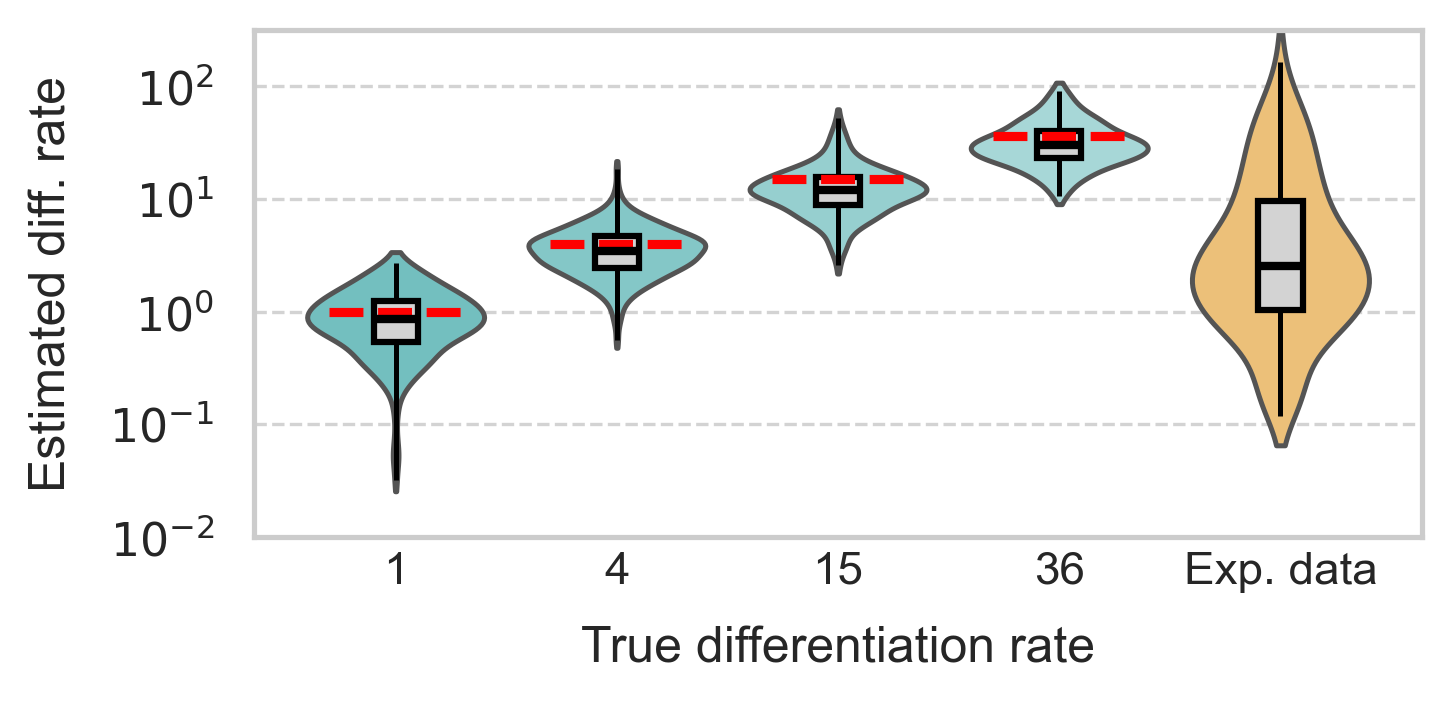

In [220]:
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(5,2.5), dpi=300)

palette = {
    0: hs[0],
    1: hs[1],
    4: hs[2],
    15: hs[3],
    36: hs[4],
    'Exp. data': '#ffc566'
}

# Violin plot
sns.violinplot(
    data=df_nonzero, x='scenario', y='log_r_median',
    order=[1, 4, 15, 36, 'Exp. data'],
    inner=None, cut=1, hue='scenario', density_norm='area',
    linewidth=1.2, palette=palette, ax=ax, legend=False
)

# Overlay boxplot
sns.boxplot(
    data=df_nonzero, x='scenario', y='log_r_median',
    order=[1, 4, 15, 36, 'Exp. data'],
    whis=np.inf, width=0.2, showcaps=False,
    boxprops={'facecolor':'lightgray', 'edgecolor':'black', 'linewidth':1.5},
    whiskerprops={'color':'black', 'linewidth':1.2},
    capprops={'color':'black', 'linewidth':1.2},
    medianprops={'color':'black', 'linewidth':2},
    ax=ax
)

# Reference lines at log10(r)
for i, r in enumerate([1, 4, 15, 36]):
    ax.hlines(
        y=np.log10(r), xmin=i-0.3, xmax=i+0.3,
        colors='red', linestyles='dashed', linewidth=2.2
    )

# Axis labels
ax.set_xlabel("True differentiation rate", fontsize=12, labelpad=8)
ax.set_ylabel("Estimated diff. rate", fontsize=12, labelpad=8)

# Set y‑ticks to powers of 10
# Choose the range based on your data
yticks = np.arange(-2, 3)   # gives 10^-2 through 10^2
ax.set_yticks(yticks)
ax.set_yticklabels([f"$10^{{{int(y)}}}$" for y in yticks])

ax.tick_params(axis='x', which='major', length=0, labelsize=11)
ax.tick_params(axis='y', labelsize=11)

ax.set_ylim([-2, 2.5])

ax.grid(True, axis='y', linestyle='--', linewidth=0.8, color='lightgray')

plt.tight_layout()
plt.show()

In [199]:
import pandas as pd
import numpy as np
from scipy.stats import ks_2samp, levene

# Subset the data
group1 = df_plot.loc[df_plot['scenario'] == 15, 'r_median']
group2 = df_plot.loc[df_plot['scenario'] == 'Exp. data', 'r_median']

# Remove NaNs and -inf
group1 = group1[~group1.isna() & (group1 != -np.inf)]
group2 = group2[~group2.isna() & (group2 != -np.inf)]

# Kolmogorov–Smirnov test (two-sample)
ks_stat, ks_pval = ks_2samp(group1, group2)

# Levene’s test (variance comparison, robust to non-normality)
lev_stat, lev_pval = levene(group1, group2)

# Variances
var1 = group1.var(ddof=1)  # sample variance
var2 = group2.var(ddof=1)

print("Kolmogorov–Smirnov test:")
print(f"  Statistic = {ks_stat:.4f}, p-value = {ks_pval:.4g}")

print("\nLevene’s test for equal variances:")
print(f"  Statistic = {lev_stat:.4f}, p-value = {lev_pval:.4g}")

print("\nSample variances:")
print(f"  Group1 variance = {var1:.4f}")
print(f"  Group2 variance = {var2:.4f}")

Kolmogorov–Smirnov test:
  Statistic = 0.7150, p-value = 9.929e-42

Levene’s test for equal variances:
  Statistic = 3.4987, p-value = 0.06229

Sample variances:
  Group1 variance = 53.1901
  Group2 variance = 372.9589


In [171]:
import pandas as pd
import numpy as np

# Subset to scenario == "real"
group2 = df.loc[(df['scenario'] == 'real') & (df['r_median'] > 0), ['r_median', 'fish']]
# group2 = df.loc[(df['scenario'] == 'real') & (df['r_median'] > 0), ['r_median', 'fish']]
group2['log_r_median'] = np.log(group2['r_median'])

# Overall mean
grand_mean = group2['log_r_median'].mean()

# Group means and sizes
group_stats = group2.groupby('fish')['log_r_median'].agg(['mean', 'count'])

# --- Between-group variance ---
# Weighted variance of group means around the grand mean
between_var = (group_stats['count'] * (group_stats['mean'] - grand_mean)**2).sum() / (group_stats['count'].sum() - 1)

# --- Within-group variance ---
# Pooled variance across groups
within_var = group2.groupby('fish').apply(lambda g: g['log_r_median'].var(ddof=1) * (len(g)-1)).sum() / (len(group2) - len(group_stats))

print("Between-group variance:", between_var)
print("Within-group variance:", within_var)

Between-group variance: 0.4364178571646695
Within-group variance: 2.1576164908698945


/var/folders/59/35nb2tq50vz3vpwjkwkzppvh0000gn/T/ipykernel_63362/3715031485.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  within_var = group2.groupby('fish').apply(lambda g: g['log_r_median'].var(ddof=1) * (len(g)-1)).sum() / (len(group2) - len(group_stats))


In [172]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

model = ols('log_r_median ~ C(fish)', data=group2).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

              sum_sq     df         F    PR(>F)
C(fish)    89.029243   23.0  1.794034  0.018544
Residual  390.528585  181.0       NaN       NaN


## Null hypothesis

In [232]:
scenarios = ['real', 'n1000_r0_y6', 'n1000_r1_y6', 'n1000_r4_y6', 'n1000_r15_y6', 'n1000_r36_y6']
scenarios_labels = ['Exp. data', 0, 1, 4, 15, 36]
mapping = dict(zip(scenarios, scenarios_labels))

df2 = df.query('scenario.isin(@scenarios)').copy()
df2['scenario'] = df2['scenario'].map(mapping)
agg_df = df2.groupby('scenario', as_index=False).agg({'pass_null': 'mean'})
agg_df['percent_pass'] = agg_df['pass_null'] * 100
agg_df

,scenario,pass_null,percent_pass
0,0,0.025000,2.500000
1,1,0.980749,98.074866
2,4,1.000000,100.000000
3,15,1.000000,100.000000
4,36,1.000000,100.000000
5,Exp. data,0.835878,83.587786


In [226]:
palette[4]

(0.4750000000000001, 0.825, 0.825)

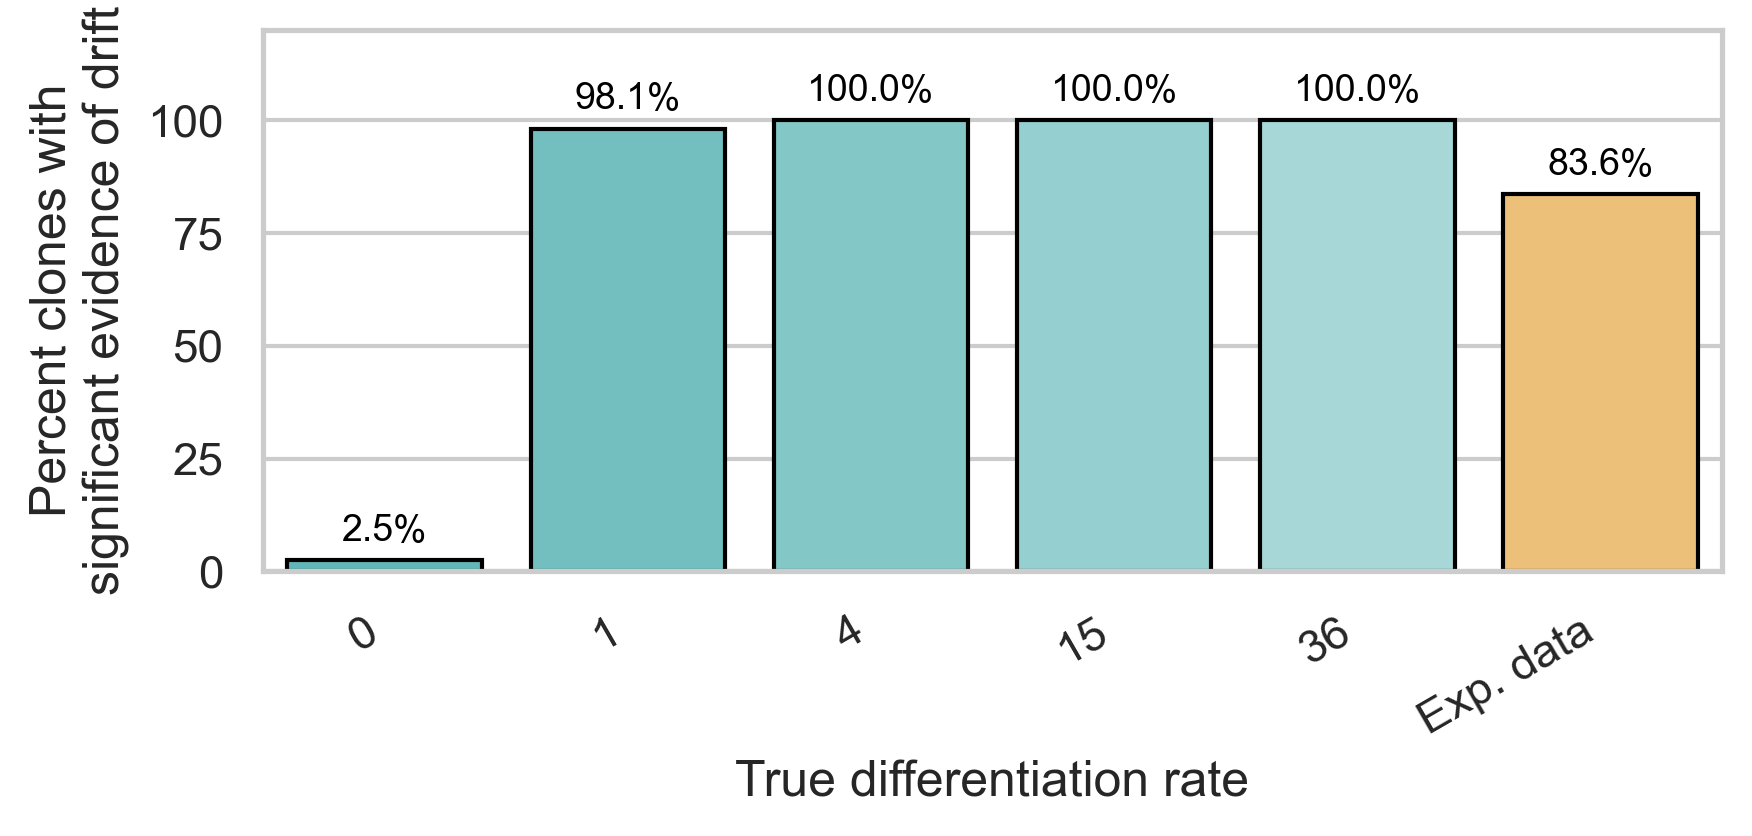

In [243]:
plt.figure(figsize=(6,3), dpi=300)
ax = sns.barplot(
    data=agg_df, x='scenario', y='percent_pass',
    edgecolor='black', hue='scenario', palette=palette, legend=False
)

plt.ylabel("Percent clones with\nsignificant evidence of drift", fontsize=12)
plt.xlabel("True differentiation rate", fontsize=12)
plt.xticks(rotation=30, ha='right')
# plt.title("% with significant evidence of drift", fontsize=13)

# Annotate values above bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.1f}%",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=9, color='black', xytext=(0, 3),
                textcoords='offset points')

ax.set_ylim(0, 120)

plt.tight_layout()
plt.show()

In [173]:
model_simulations_path = os.path.abspath("../model_simulations")

# Add to sys.path if not already present
if model_simulations_path not in sys.path:
    sys.path.append(model_simulations_path)

print("Added to path:", model_simulations_path)
from saving_loading import find_scenarios, load_all_scenarios

scenarios_directory = os.path.join('..', 'model_simulations', 'scenarios')
fish_data, clone_data = load_all_scenarios('real', directory = scenarios_directory)

Added to path: /Users/connor/Documents/github/sperm-data-analysis/model_simulations


In [174]:
f = 4
df.query('fish == @f and scenario == "real"')[['r_median', 'lower', 'upper', 'l_gap']]

,r_median,lower,upper,l_gap
13872,11.606742,1.668735,80.729671,3.613132e+01
13873,5.997460,0.790167,45.521399,4.063773e+01
13874,0.000000,0.000000,3.765230,-1.421085e-14
13875,1.176729,0.082311,16.822668,5.724062e+00
13876,1.025974,0.056183,18.735676,4.425705e+00
13877,1.013537,0.163815,6.270837,1.365544e+01
13878,0.205108,0.017620,2.387617,4.388477e+00


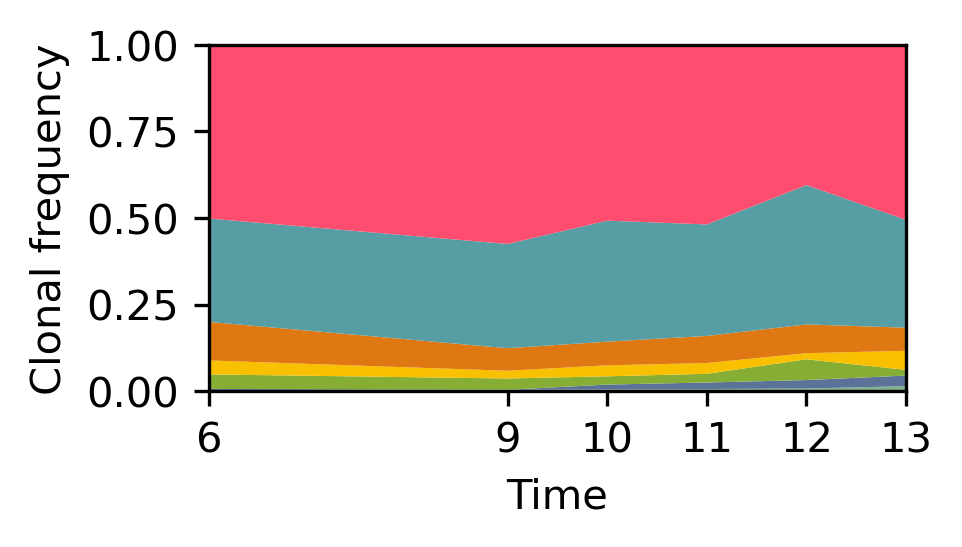

In [177]:
# plt.style.use('default')
fig, ax = plt.subplots(figsize = (3, 1.5), dpi=300)
tm.visualize.plot(fish_data['real', f], ax = ax)

In [45]:
colors = np.array(["#ff4d6f", "#579ea4", "#df7713", "#f9c000", "#86ad34",
              "#5d7298", "#81b28d", "#7e1a2f", "#2d2651", "#c8350d", "#bd777a"])

In [72]:
import numpy as np
import matplotlib.colors as mcolors

colors = np.array([
    "#ff4d6f", "#579ea4", "#df7713", "#f9c000", "#86ad34",
    "#5d7298", "#81b28d", "#7e1a2f", "#2d2651", "#c8350d", "#bd777a"
])

def dim_colors(colors, target_index, alpha=0.6):
    """
    Dim all colors except the one at target_index by blending with white.
    alpha controls how much white is mixed in (0=no dimming, 1=fully white).
    """
    new_colors = []
    for j, c in enumerate(colors):
        rgb = np.array(mcolors.to_rgb(c))
        if j == target_index:
            new_colors.append(c)  # keep original
        else:
            # blend toward white
            rgb_dim = (1 - alpha) * rgb + alpha * np.array([1, 1, 1])
            new_colors.append(mcolors.to_hex(rgb_dim))
    return np.array(new_colors)

# Example: keep index 2 bright, dim others
dimmed = dim_colors(colors, target_index=2, alpha=0.7)
print(dimmed)

['#ffcad4' '#cde2e4' '#df7713' '#fdecb2' '#dbe6c2' '#ced5e0' '#d9e8dd'
 '#d8bac1' '#c0becb' '#eec2b6' '#ebd6d7']


Text(0, 0.5, '')

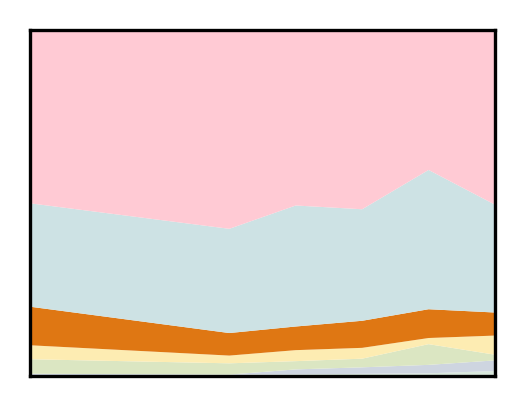

In [73]:
fig, ax = plt.subplots(figsize = (2, 1.5), dpi=300)
tm.visualize.plot(fish_data['real', f], ax = ax, colors = dimmed)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('')
ax.set_ylabel('')

In [79]:
real_df['r_median'].median()

1.374161182573631

In [200]:
scenario = "real"
real_df = df.query('scenario == @scenario')
num_real = len(real_df)
prop_drift = real_df['pass_null'].mean()
print(f'Of the {num_real} experimental clones, {100*prop_drift:.1f}% show significant evidence of drifting.')

Of the 262 experimental clones, 83.6% show significant evidence of drifting.


In [205]:
df.query('scenario == "real" and ~pass_null').sort_values('init_freq', ascending = False).head(3)

,scenario,fish,clone,init_time,init_freq,last_time,max_time,max_freq,size,avg_freq_change,...,if_opt,l_max,lower,upper,if_null,l_null,r_median,log_r_median,l_gap,pass_null
13900,real,42,1,4.86,0.281088,14.23,14.23,0.278607,0.269932,0.000265,...,0.196587,-85.279100,0.0,2.240837,0.196587,-85.279100,0.0,-inf,0.000000,False
13756,real,16,0,8.86,0.278824,12.10,12.10,0.268873,0.274912,0.003071,...,0.222817,-46.969298,0.0,67.910907,0.228711,-48.534413,0.0,-inf,1.565115,False
13757,real,16,1,8.86,0.247059,12.10,12.10,0.266805,0.247907,-0.006094,...,0.195245,-44.835681,0.0,13.019510,0.206253,-45.628951,0.0,-inf,0.793269,False


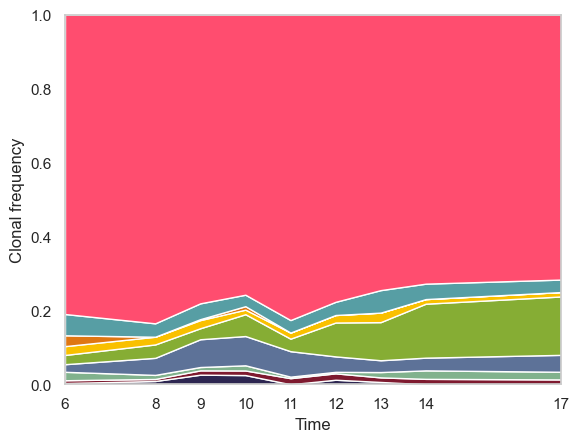

In [204]:
tm.visualize.plot(fish_data['real', 22])

## Dependence on initial frequency

In [178]:
# Subset to only the "real" scenario
df_real = df.query('scenario == "real" and ~r_median.isna()').copy()

# Make sure pass_null is numeric (0/1)
df_real["pass_null"] = df_real["pass_null"].astype(int)

# Logistic regression: pass_null ~ init_freq
logit_model_real = smf.logit("pass_null ~ init_freq", data=df_real).fit()

print(logit_model_real.summary())
print(logit_model_real.pvalues)

Optimization terminated successfully.
         Current function value: 0.437944
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:              pass_null   No. Observations:                  259
Model:                          Logit   Df Residuals:                      257
Method:                           MLE   Df Model:                            1
Date:                Mon, 24 Nov 2025   Pseudo R-squ.:                 0.02576
Time:                        10:11:55   Log-Likelihood:                -113.43
converged:                       True   LL-Null:                       -116.43
Covariance Type:            nonrobust   LLR p-value:                   0.01432
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.3432      0.199      6.754      0.000       0.953       1.733
init_freq      4.0535      2.

In [179]:
x_vals = np.linspace(df_real['init_freq'].min(),
                     df_real['init_freq'].max(),
                     200)   # 200 evenly spaced points

# Build a dataframe for prediction
pred_df = pd.DataFrame({'init_freq': x_vals})

# Get predicted probabilities
pred_summary = logit_model_real.get_prediction(pred_df).summary_frame()

# This gives columns: mean, mean_ci_lower, mean_ci_upper
# Rename for clarity
pred_summary = pred_summary.rename(columns={
    'mean': 'predicted',
    'mean_ci_lower': 'ci_lower',
    'mean_ci_upper': 'ci_upper'
})

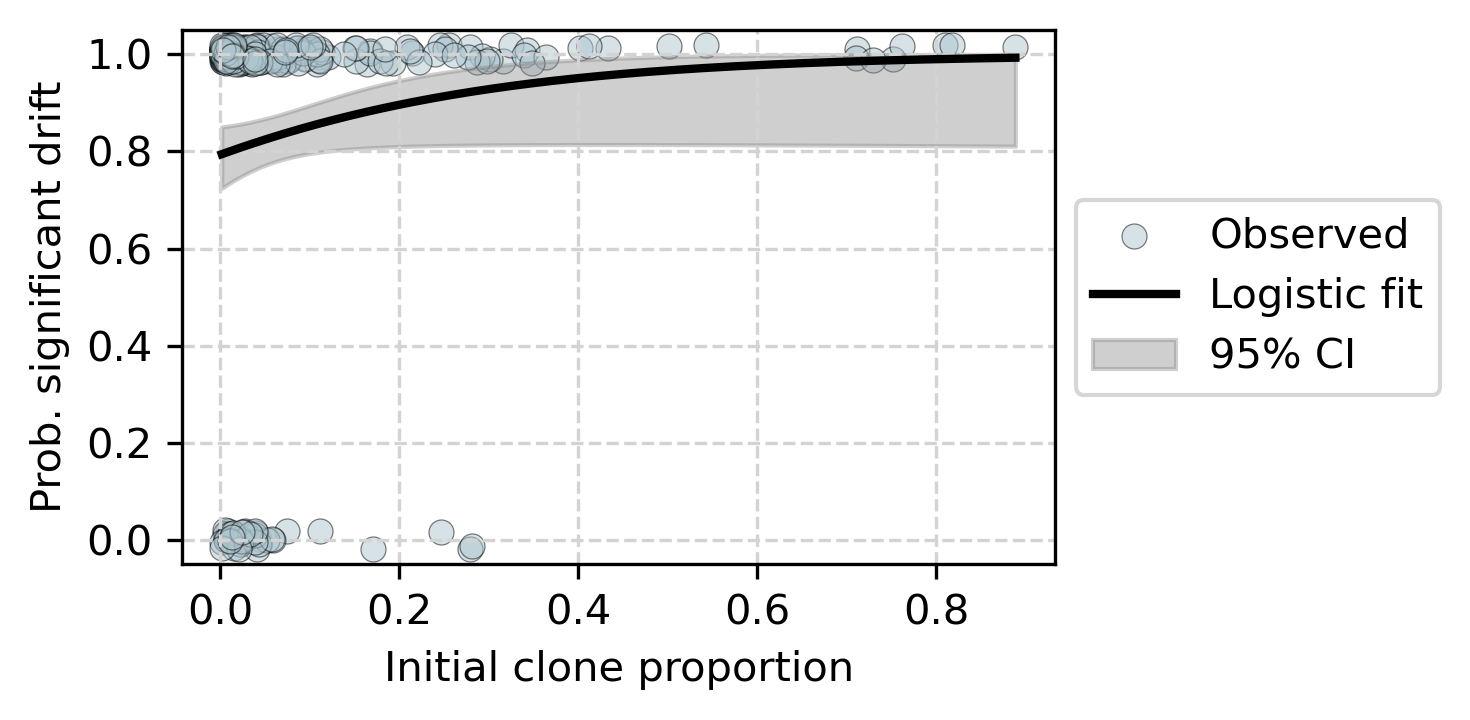

In [180]:
# Plot observed data (jittered vertically for clarity)
plt.figure(figsize=(5,2.5), dpi=300)

plt.scatter(df_real['init_freq'],
            df_real['pass_null'] + np.random.uniform(-0.02,0.02,len(df_real)),
            alpha=0.5, color="#AEC6CF", edgecolor="black", linewidth=0.3,
            label="Observed")

# Plot logistic curve
plt.plot(x_vals, pred_summary['predicted'], color="black", linewidth=2, label="Logistic fit")

# Add confidence/error bands with a different color
plt.fill_between(x_vals,
                 pred_summary['ci_lower'],
                 pred_summary['ci_upper'],
                 color="#888888", alpha=0.4, label="95% CI")  # peach color

# Labels and styling
plt.xlabel("Initial clone proportion")
plt.ylabel("Prob. significant drift")
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle="--", linewidth=0.8, color="lightgray")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

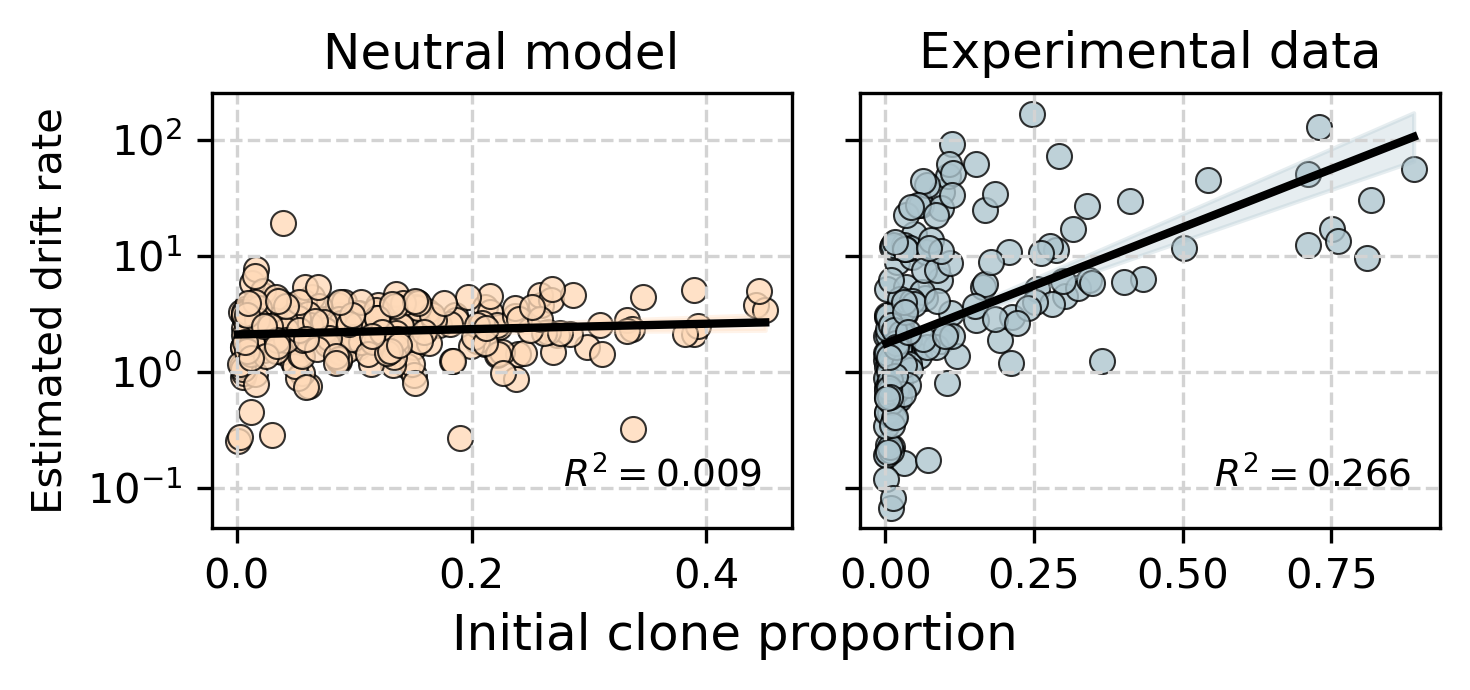

In [181]:
# Subset
compare_sim = "n1000_r2.5_y6"
real = df.query('scenario == "real" and ~r_median.isna() and r_median > 0').copy()
sim  = df.query('scenario == @compare_sim and ~r_median.isna() and r_median > 0 and fish < 30').copy()

# Fit regressions
slope_real, intercept_real, r_real, p_real, stderr_real = linregress(real['init_freq'], real['log_r_median'])
slope_sim, intercept_sim, r_sim, p_sim, stderr_sim = linregress(sim['init_freq'], sim['log_r_median'])

# Pastel palette
pastel_blue   = "#AEC6CF"  # soft blue
pastel_orange = "#FFDAB9"  # peach
line_color    = "#000000"  # muted gray for regression lines

# X values for smooth line
x_real = np.linspace(real['init_freq'].min(), real['init_freq'].max(), 200)
x_sim  = np.linspace(sim['init_freq'].min(), sim['init_freq'].max(), 200)

# Predicted values
y_real = intercept_real + slope_real * x_real
y_sim  = intercept_sim + slope_sim * x_sim

# Error regions (±1 stderr on slope, approximate)
y_real_upper = intercept_real + (slope_real + stderr_real) * x_real
y_real_lower = intercept_real + (slope_real - stderr_real) * x_real

y_sim_upper = intercept_sim + (slope_sim + stderr_sim) * x_sim
y_sim_lower = intercept_sim + (slope_sim - stderr_sim) * x_sim

# Plot
fig, axes = plt.subplots(1, 2, figsize=(5,2.5), dpi=300, sharey=True)

# Sim scenario
axes[0].scatter(sim['init_freq'], sim['log_r_median'], color=pastel_orange, alpha=0.8, edgecolor="black", linewidth=0.5)
axes[0].plot(x_sim, y_sim, color=line_color, linewidth=2)
axes[0].fill_between(x_sim, y_sim_lower, y_sim_upper, color=pastel_orange, alpha=0.3)
axes[0].set_title(f"Neutral model")
axes[0].set_ylabel("Estimated drift rate")

# Real scenario
axes[1].scatter(real['init_freq'], real['log_r_median'], color=pastel_blue, alpha=0.8, edgecolor="black", linewidth=0.5)
axes[1].plot(x_real, y_real, color=line_color, linewidth=2)
axes[1].fill_between(x_real, y_real_lower, y_real_upper, color=pastel_blue, alpha=0.3)
axes[1].set_title(f"Experimental data")

# Y-axis ticks
yticks = np.arange(-1, 3)   # gives 10^-2 through 10^2
axes[0].set_yticks(yticks)
axes[0].set_yticklabels([f"$10^{{{int(y)}}}$" for y in yticks])

# Grid styling
for ax in axes:
    ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray')

fig.supxlabel("Initial clone proportion", y=0.1)

# Annotate R^2 values at bottom right of each axis
axes[0].text(0.95, 0.075, f"$R^2 = {r_sim**2:.3f}$",
             transform=axes[0].transAxes, ha='right', va='bottom', fontsize=9)
axes[1].text(0.95, 0.075, f"$R^2 = {r_real**2:.3f}$",
             transform=axes[1].transAxes, ha='right', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [185]:
df_hypothesis = df.query('~r_median.isna() and r_median > 0 and scenario in ["real", "n1000_r2.5_y6"]')
df_hypothesis = df_hypothesis[~((df_hypothesis['scenario'] == "n1000_r2.5_y6") & (df_hypothesis['fish'] >= 30))]

import statsmodels.formula.api as smf
model = smf.ols("log_r_median ~ init_freq * scenario", data=df_hypothesis).fit()
print(model.summary())
print(model.pvalues)

                            OLS Regression Results                            
Dep. Variable:           log_r_median   R-squared:                       0.238
Model:                            OLS   Adj. R-squared:                  0.233
Method:                 Least Squares   F-statistic:                     48.13
Date:                Mon, 24 Nov 2025   Prob (F-statistic):           4.41e-27
Time:                        11:18:00   Log-Likelihood:                -254.27
No. Observations:                 466   AIC:                             516.5
Df Residuals:                     462   BIC:                             533.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

In [186]:
df_hypothesis = df.query('~r_median.isna() and r_median > 0 and scenario in ["real", "n1000_r2.5_y6"]')
df_hypothesis = df_hypothesis[~((df_hypothesis['scenario'] == "n1000_r2.5_y6") & (df_hypothesis['fish'] >= 30))]

import statsmodels.formula.api as smf
model = smf.ols("log_r_median ~ init_freq * scenario", data=df_hypothesis).fit()
print(model.summary())
print(model.pvalues)

                            OLS Regression Results                            
Dep. Variable:           log_r_median   R-squared:                       0.238
Model:                            OLS   Adj. R-squared:                  0.233
Method:                 Least Squares   F-statistic:                     48.13
Date:                Mon, 24 Nov 2025   Prob (F-statistic):           4.41e-27
Time:                        11:18:02   Log-Likelihood:                -254.27
No. Observations:                 466   AIC:                             516.5
Df Residuals:                     462   BIC:                             533.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           